# Stage A: Data Preparation

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from src import utils, encoders
from src.splits import loadProtocolSubset
from src.visualization import displayRankedImageList, displayPrecisionRecallCurve
from src.visualization import RelevantVisualWordsDisplay
import os

def loadEncodingSubset(category, encoding, subset="train", root_dir="data"):
    base_dir = f"{root_dir}/encodings/{encoding}/"
    pos_file = f"{base_dir}/{category}_{subset}.npz"
    neg_file = f"{base_dir}/background_{subset}.npz"
            
    p_data = np.load(pos_file)
    p_hist, p_name = p_data['histograms'], p_data['file_names']
    p_label = np.ones(len(p_name), dtype=np.int32)

    n_data = np.load(neg_file)
    n_hist, n_name = n_data['histograms'], n_data['file_names']
    n_label = -np.ones(len(n_name), dtype=np.int32)

    hist = np.concatenate([p_hist, n_hist], axis=0)
    names = np.concatenate([p_name, n_name], axis=0)
    labels = np.concatenate([p_label, n_label], axis=0)
    
    return hist, labels, names

def get_subset(histograms, names, labels, fraction):
    num_images = len(labels)
    if np.isinf(fraction):
        num_selected = num_images
    elif fraction < 1:
        num_selected = int(np.ceil(fraction * num_images))
    else:
        num_selected = int(fraction)

    # shuffle the training data
    rng = np.random.default_rng()
    sel = rng.choice(num_images, size=num_selected, replace=False)
    names = [names[i] for i in sel]
    histograms = histograms[sel,:]
    labels = labels[sel]
    return histograms, names, labels

def printDatasetStats(histograms, names, labels, subset="train"):
    # count how many images are there
    print("Number of {:5s} images: {:5d} positive ({:.2%}), {:5d} negative ({:.2%}), total: {:5d}".format(subset,
        sum(labels > 0), 
        sum(labels > 0)/len(labels), 
        sum(labels < 0), 
        sum(labels < 0)/len(labels),
        len(labels)
        )
    )

def l2norm(x):
    return x/(np.sum(x**2, axis=1, keepdims=True)**0.5 + 1e-10) # l2 norm


In [3]:
encoding = "bovw_K512_C0"
# encoding = "vlad_K32_C80"
# encoding = "fv_K32_C80"

category = "motorbike"
# category = "aeroplane"
# category = "person"

# Load training data
histograms, labels, names = loadProtocolSubset(category, encoding, subset="train")

# Load testing data
testHistograms, testLabels, testNames = loadProtocolSubset(category, encoding, subset="val")

################################################################################
# Throw away part of the training data
################################################################################

# histograms, names, labels = get_subset(histograms, names, labels, 0.1)
# histograms, names, labels = get_subset(histograms, names, labels, 0.5)
histograms, names, labels = get_subset(histograms, names, labels, np.inf)

################################################################################
# Show some statistics about the dataset
################################################################################
print("Encoding : {}\nCategory: {}\nEncoding Size: {}".format(encoding, category, histograms.shape[1]))
printDatasetStats(histograms, names, labels, subset="train")
printDatasetStats(testHistograms, testNames, testLabels, subset="test")

################################################################################
# Vary the image representation
################################################################################
# histograms = encoders.removeSpatialInformation(histograms)
# testHistograms = encoders.removeSpatialInformation(testHistograms)

################################################################################
# Vary the classifier (Hellinger kernel)
################################################################################
# ** insert code here for the Hellinger kernel using  **
# ** the training histograms and testHistograms       **

# L2 normalize the histograms before running the linear SVM
histograms = l2norm(histograms)
testHistograms = l2norm(testHistograms)

print("Training histograms shape:", histograms.shape)
print("Testing histograms shape:", testHistograms.shape)


Encoding : bovw_K512_C0
Category: motorbike
Encoding Size: 2048
Number of train images:    96 positive (10.54%),   815 negative (89.46%), total:   911
Number of test  images:    24 positive (10.53%),   204 negative (89.47%), total:   228
Training histograms shape: (911, 2048)
Testing histograms shape: (228, 2048)


# Stage B: Training a classifier

Train the linear SVM. The SVM paramter C should be cross-validated. 
Here for simplicity we pick a valute that works well with all kernels.

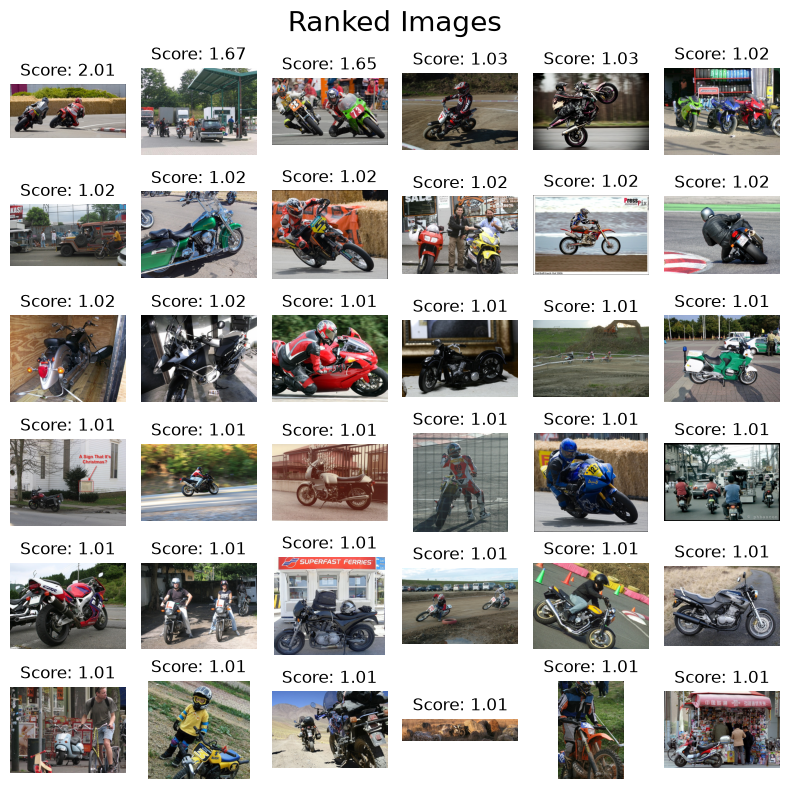

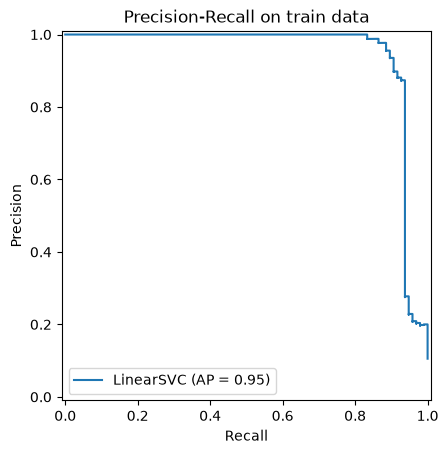

In [4]:
# Configure and train the linear SVM
W, b = utils.train_svm(histograms, labels, C=10)

# # Evaluate the scores on the training data
scores = (W @ histograms.T  + b)

# Visualize the ranked list of images
full_paths = [f"data/images/{name}.jpg" for name in names]
displayRankedImageList(scores, full_paths, uniform=False, figzize=(8, 8))

# Visualize the precision-recall curve
_ = displayPrecisionRecallCurve(labels, scores, title="Precision-Recall on train data")


# Stage C: Classify the test images and assess the performance

In [ ]:

# Test the linear SVM
testScores = W @ testHistograms.T + b
# testScores = svm.decision_function(testHistograms)

# Print Results
perm = np.argsort(testScores)[::-1]
print('Correctly retrieved in the top 36: {:d}'.format(sum(testLabels[perm[:36]] > 0)))

# Visualize the ranked list of images
full_paths = [f"data/images/{name}.jpg" for name in testNames]
displayRankedImageList(testScores, full_paths, uniform=False, figzize=(8, 8))

# Visualize the precision-recall curve
*_, ap= displayPrecisionRecallCurve(testLabels, testScores, title="Precision-Recall on test data")
print(f"Average Precision (AP) on test data: {ap:.4f}")

In [ ]:
max_idx = np.argmax(testScores)
image_name = testNames[max_idx]

# print(testNames[max_idx])
assert "bovw" in encoding, "only works for BOVW encoding"
encoder = encoders.ImageEncoder(f"data/encoders/{encoding}.npz")
img_file = "data/images/{}.jpg".format(testNames[max_idx])
img = encoders.standarizeImage(img_file)
rvwdisplay = RelevantVisualWordsDisplay(img, W, encoder)
import ipywidgets as widgets
@widgets.interact(rank=(0, len(rvwdisplay)-1))
def display_relevant_visual_words(rank=0):
    rvwdisplay.plot(rank, figsize=(12, 8))
